# 07 - Recommendations

**Goal:** turn the findings from notebooks 02-06 into prioritized, quantified actions.

**Inputs:** `data/processed/` outputs of the earlier notebooks and `transactions_clean.csv`
**Output:** `data/processed/recommendations.csv`

**How sizing works.** Each recommendation has a *measured base* (a number taken straight from the data) and a *scenario range* (an assumption about how much of that base an action could change). The base is evidence; the scenario percentages are assumptions, labelled as such, and should be replaced with real campaign results once available.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from pathlib import Path

ROOT = Path.cwd().parent  # notebook runs from notebooks/
PROCESSED_DIR = ROOT / "data" / "processed"
FIGURES_DIR = ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:,.2f}".format)

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / f"{name}.png", dpi=150)

In [2]:
df = pd.read_csv(
    PROCESSED_DIR / "transactions_clean.csv",
    parse_dates=["invoice_date", "invoice_month", "first_purchase_month"],
    dtype={"invoice": str, "stock_code": str, "customer_id": "Int64"},
)
sales = df[~df.is_cancellation]
cancels = df[df.is_cancellation]
tracked = sales[sales.has_customer]  # customer-level analysis only

LAST_FULL_MONTH = pd.Timestamp("2011-11-01")  # data ends 9 Dec 2011 (partial month)

## 1. Measured bases

In [3]:
risk = pd.read_csv(PROCESSED_DIR / "at_risk_customers.csv", parse_dates=["last_purchase"])
rfm = pd.read_csv(PROCESSED_DIR / "rfm_customers.csv")
backtest = pd.read_csv(PROCESSED_DIR / "churn_rule_backtest.csv").set_index("rule")
new_by_month = pd.read_csv(PROCESSED_DIR / "new_customers_by_month.csv", parse_dates=["cohort"])

# --- Win-back: customers silent > 90 days with positive trailing sales
flagged = risk[risk.flag_90d & (risk.trailing_rev > 0)]
precision = backtest.loc["silent > 90 days", "precision"]
bases = {
    "flagged_customers": len(flagged),
    "flagged_trailing_rev": flagged.trailing_rev.sum(),
    "expected_loss": flagged.trailing_rev.sum() * precision,   # only 'precision' of them truly churn
    "top_tier_customers": int((flagged.value_quintile == 5).sum()),
    "top_tier_trailing_rev": flagged.loc[flagged.value_quintile == 5, "trailing_rev"].sum(),
}
print(f"back-test precision of the 90-day rule: {precision:.1%}")
pd.Series(bases).to_frame("value")

back-test precision of the 90-day rule: 60.6%


,value
flagged_customers,"1,365.00"
flagged_trailing_rev,"808,607.10"
expected_loss,"490,012.44"
top_tier_customers,60.00
top_tier_trailing_rev,"218,262.44"


In [4]:
# --- Protect the core: Champions + Loyal customers' trailing 12-month sales
core = rfm[rfm.segment.isin(["Champions", "Loyal"])].merge(risk[["customer_id", "trailing_rev"]], on="customer_id", how="left")
core_trailing = core.trailing_rev.fillna(0).sum()
total_trailing = risk.trailing_rev.sum()
print(f"Champions + Loyal: {len(core):,} customers ({len(core) / len(rfm):.0%}), "
      f"trailing 12m net sales £{core_trailing:,.0f} ({core_trailing / total_trailing:.0%} of active customers' sales)")

Champions + Loyal: 1,870 customers (32%), trailing 12m net sales £6,677,419 (84% of active customers' sales)


In [5]:
# --- Acquisition gap: Jun-Nov new customers, 2011 vs 2010
window = new_by_month[new_by_month.cohort.dt.month.between(6, 11) & new_by_month.cohort.dt.year.isin([2010, 2011])].copy()
window["total"] = window.UK + window["Non-UK"]
by_year = window.groupby(window.cohort.dt.year)[["UK", "Non-UK", "total"]].sum()
gap = int(by_year.loc[2010, "total"] - by_year.loc[2011, "total"])
print(by_year)
print(f"gap: {gap} fewer new customers in Jun-Nov 2011 than in Jun-Nov 2010")

          UK  Non-UK  total
cohort                     
2010    1422     141   1563
2011     811     106    917
gap: 646 fewer new customers in Jun-Nov 2011 than in Jun-Nov 2010


In [6]:
# Value of a new customer: net sales in the first 365 days, for Jun-Nov 2010 cohorts (all have a full year of data)
tx = df[df.has_customer].copy()
first_ts = tx[~tx.is_cancellation].groupby("customer_id").invoice_date.min().rename("first_ts")
tx = tx.join(first_ts, on="customer_id")
cohort_2010 = tx[tx.first_purchase_month.between("2010-06-01", "2010-11-01") & (tx.invoice_date <= tx.first_ts + pd.Timedelta(days=365))]
first_year = cohort_2010.groupby("customer_id").line_total.sum().round(2)
first_year = first_year[first_year > 0]

value = pd.Series({
    "customers": len(first_year),
    "median first-year net sales": first_year.median(),
    "mean first-year net sales": first_year.mean(),
    "share with only one order year-1": (cohort_2010[~cohort_2010.is_cancellation].groupby("customer_id").invoice.nunique() == 1).mean(),
})
value.to_frame("value")

,value
customers,"1,545.00"
median first-year net sales,574.40
mean first-year net sales,"1,305.93"
share with only one order year-1,0.36


In [7]:
# --- Leakage: cancellations and untracked guest orders
gross = sales.line_total.sum()
cancelled = -cancels.line_total.sum()
guest_sales = sales.loc[~sales.has_customer, "line_total"].sum()
print(f"cancelled value £{cancelled:,.0f} ({cancelled / gross:.1%} of gross sales)")
print(f"guest-order sales £{guest_sales:,.0f} ({guest_sales / gross:.1%}) over two years, about £{guest_sales / 2:,.0f} a year")

cancelled value £1,462,424 (7.1% of gross sales)
guest-order sales £3,101,456 (15.1%) over two years, about £1,550,728 a year


## 2. Sizing scenarios

Scenario rates are **assumptions**, not predictions.

| # | Action | Measured base | Scenario assumption (low / mid / high) |
|---|---|---|---|
| 1 | Win back silent customers | Expected loss from flagged customers | 10% / 20% / 30% of expected loss recovered |
| 2 | Protect Champions and Loyal buyers | Their trailing 12m net sales | Avoid 1% / 2% / 3% of that revenue leaking away |
| 3 | Restore new-customer acquisition | Customer gap vs 2010 x median first-year sales | 25% / 50% / 100% of the gap closed |
| 4 | Cut entry-error cancellations and track guest orders | Cancelled value; guest sales | 10% / 20% / 30% of one year's cancelled value avoided |

In [8]:
def scenarios(base, rates):
    return [base * r for r in rates]

median_value = first_year.median()
annual_cancelled = cancelled / 2  # two years of data

recs = pd.DataFrame([
    {
        "rank": 1,
        "recommendation": "Win back high-value customers silent for more than 90 days",
        "evidence": f"{bases['flagged_customers']:,} customers flagged, £{bases['flagged_trailing_rev'] / 1e3:,.0f}K trailing sales; the rule catches 75% of churners; top tier is {bases['top_tier_customers']} customers worth £{bases['top_tier_trailing_rev'] / 1e3:,.0f}K",
        "base_gbp": bases["expected_loss"],
        "scenario_assumption": "10% / 20% / 30% of expected loss recovered",
        "low_gbp": scenarios(bases["expected_loss"], [0.10, 0.20, 0.30])[0],
        "mid_gbp": scenarios(bases["expected_loss"], [0.10, 0.20, 0.30])[1],
        "high_gbp": scenarios(bases["expected_loss"], [0.10, 0.20, 0.30])[2],
        "effort": "Low",
        "confidence": "High (data-backed rule); recovery rate unknown",
    },
    {
        "rank": 2,
        "recommendation": "Protect Champions and Loyal buyers with a per-customer reorder alert (1.5x their own average gap)",
        "evidence": f"{len(core):,} customers ({len(core) / len(rfm):.0%}) deliver {core_trailing / total_trailing:.0%} of trailing sales; churn rises steeply with silence, so earlier contact matters",
        "base_gbp": core_trailing,
        "scenario_assumption": "1% / 2% / 3% of their revenue protected",
        "low_gbp": core_trailing * 0.01,
        "mid_gbp": core_trailing * 0.02,
        "high_gbp": core_trailing * 0.03,
        "effort": "Low",
        "confidence": "Medium (alert precision 43% vs 28% base rate)",
    },
    {
        "rank": 3,
        "recommendation": "Find out why new-customer acquisition fell 41% and restore it (UK first)",
        "evidence": f"{gap} fewer new customers in Jun-Nov 2011 than 2010 (UK -43%); first-order value and 90-day repeat rate held steady, so volume, not quality, is the issue",
        "base_gbp": gap * median_value,
        "scenario_assumption": "25% / 50% / 100% of the customer gap closed, valued at median first-year sales",
        "low_gbp": gap * median_value * 0.25,
        "mid_gbp": gap * median_value * 0.50,
        "high_gbp": gap * median_value * 1.00,
        "effort": "Medium-High",
        "confidence": "Medium (the data has no channel or marketing information to explain the drop)",
    },
    {
        "rank": 4,
        "recommendation": "Add order-entry checks for sale-then-cancel errors and capture customer IDs on guest orders",
        "evidence": f"Cancellations are {cancelled / gross:.1%} of sales; about a quarter of cancelled value was reversed within an hour; guest orders are {guest_sales / gross:.0%} of sales and cannot be retained",
        "base_gbp": annual_cancelled,
        "scenario_assumption": "10% / 20% / 30% of a year's cancelled value avoided",
        "low_gbp": annual_cancelled * 0.10,
        "mid_gbp": annual_cancelled * 0.20,
        "high_gbp": annual_cancelled * 0.30,
        "effort": "Low-Medium",
        "confidence": "Low-Medium (cancellations do not drive churn; this is cost and data quality)",
    },
])
recs[["rank", "recommendation", "base_gbp", "low_gbp", "mid_gbp", "high_gbp", "effort", "confidence"]]

,rank,recommendation,base_gbp,low_gbp,mid_gbp,high_gbp,effort,confidence
0,1,Win back high-value customers silent for more ...,"490,012.44","49,001.24","98,002.49","147,003.73",Low,High (data-backed rule); recovery rate unknown
1,2,Protect Champions and Loyal buyers with a per-...,"6,677,419.01","66,774.19","133,548.38","200,322.57",Low,Medium (alert precision 43% vs 28% base rate)
2,3,Find out why new-customer acquisition fell 41%...,"371,062.40","92,765.60","185,531.20","371,062.40",Medium-High,Medium (the data has no channel or marketing i...
3,4,Add order-entry checks for sale-then-cancel er...,"731,212.09","73,121.21","146,242.42","219,363.63",Low-Medium,Low-Medium (cancellations do not drive churn; ...


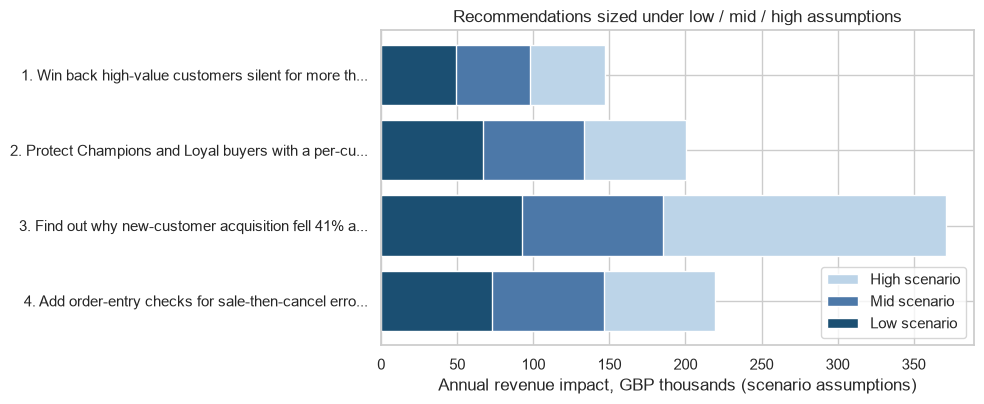

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.2))
y = np.arange(len(recs))[::-1]
ax.barh(y, recs.high_gbp / 1e3, color="#bcd4e8", label="High scenario")
ax.barh(y, recs.mid_gbp / 1e3, color="#4C78A8", label="Mid scenario")
ax.barh(y, recs.low_gbp / 1e3, color="#1b4f72", label="Low scenario")
ax.set_yticks(y, [f"{r}. {t[:48]}..." for r, t in zip(recs["rank"], recs.recommendation)])
ax.set_xlabel("Annual revenue impact, GBP thousands (scenario assumptions)")
ax.set_title("Recommendations sized under low / mid / high assumptions")
ax.legend(loc="lower right")
save(fig, "07_recommendation_impact")
plt.show()

## 3. Save

In [10]:
recs.to_csv(PROCESSED_DIR / "recommendations.csv", index=False)
print(f"saved {len(recs)} recommendations")

saved 4 recommendations


## 4. Summary for the business

1. **Win back silent high-value customers.** Start with the 60 top-tier customers on the live at-risk list, then widen to everyone silent for more than 90 days.
2. **Protect the core.** About a quarter of customers produce most of the revenue. Alert account managers when one of them passes 1.5x their own normal gap.
3. **Rebuild acquisition.** Sales are flat while new-customer acquisition fell, and cohort quality held steady, so acquisition is the part worth investigating. Find out what changed in 2011 and, if it is a fixable cause, address it, starting with the UK.
4. **Tidy the leaks.** Check unusually large orders at entry and capture customer IDs on guest orders. This is mostly cost and data quality, not retention.

### What this analysis cannot tell you
- Why acquisition fell (no marketing or channel data).
- What a win-back campaign will actually recover; run a small test with a holdout group before scaling.
- Causes: product mix has only a small association with churn (notebook 11), but nothing here shows what would change customer behaviour.